In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df_alunos = pd.read_csv("alunos_senai_sig.csv")

GRAFICO EM PIZZA - porcentagem de alunos em cada turma

Curso
Banco de Dados    10
Design            15
Java              15
Python            20
dtype: int64


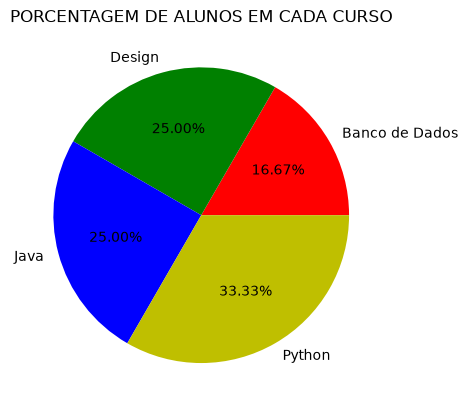

In [2]:
contagem_de_cursos = df_alunos.groupby('Curso').size()
print(contagem_de_cursos)

pizza = plt.pie(
    contagem_de_cursos.values,
    labels=contagem_de_cursos.index,
    autopct='%1.2f%%',
    colors=['r', 'g', 'b', 'y'],
)

plt.title("PORCENTAGEM DE ALUNOS EM CADA CURSO")
plt.show()

GRAFICO DE MÉDIA DE CADA TURMA

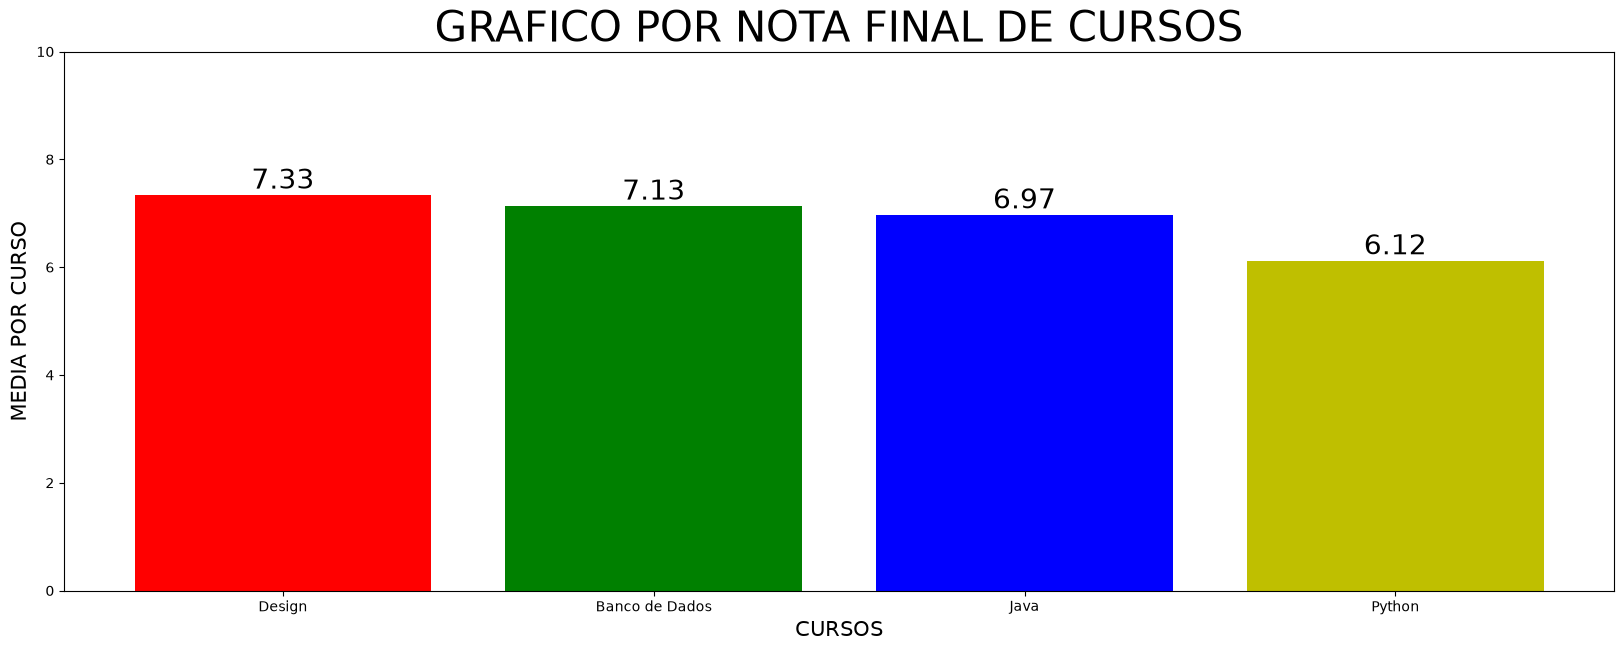

In [3]:
plt.figure(figsize=(20,7))

media_por_curso = df_alunos.groupby('Curso')["Media_Final"].mean().sort_values(ascending=False)

barra = plt.bar(
    media_por_curso.index,
    media_por_curso.values,
    color=['r', 'g', 'b', 'y'],

)

plt.title("GRAFICO POR NOTA FINAL DE CURSOS", fontsize=30)
plt.ylabel("MEDIA POR CURSO", fontsize=15)
plt.xlabel("CURSOS", fontsize=15)
plt.ylim(0,10)

for coluna in barra:
    yvalor = coluna.get_height()
    plt.text(
        coluna.get_x() + coluna.get_width()/2,
        yvalor,
        f'{yvalor:.2f}',
        fontsize=20,
        ha='center',
        va='bottom',
    )

plt.show()

MEDIA DE NOTAS INDIVUAL POR ALUNOS DO CURSO

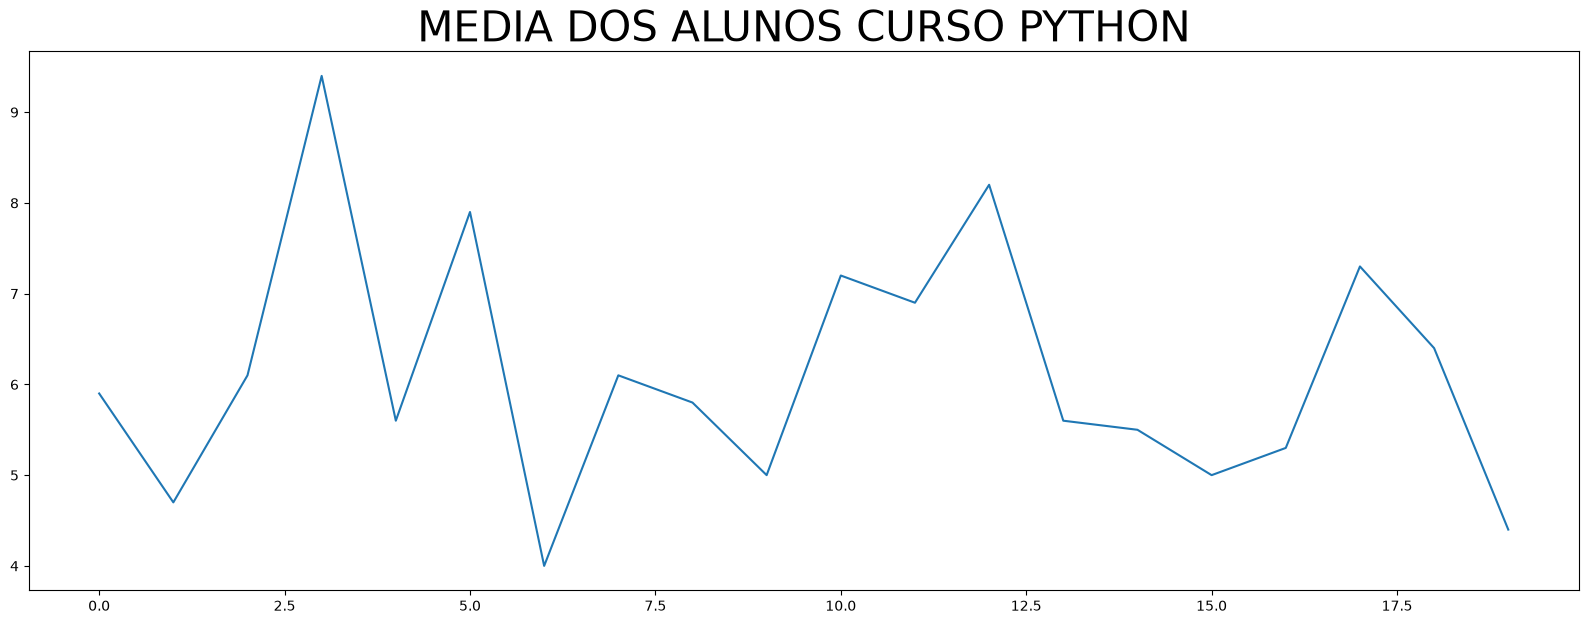

In [4]:
notas_python =  df_alunos[
    df_alunos["Curso"] == "Python"
].reset_index(drop=True)

plt.figure(figsize=(20,7))

plt.plot(
    notas_python.index,
    notas_python["Media_Final"],
)

plt.title("MEDIA DOS ALUNOS CURSO PYTHON", fontsize=30)
plt.savefig("media_final_alunos_curso_python.png")

plt.show()

LIDANDO COM SUBPLOTS

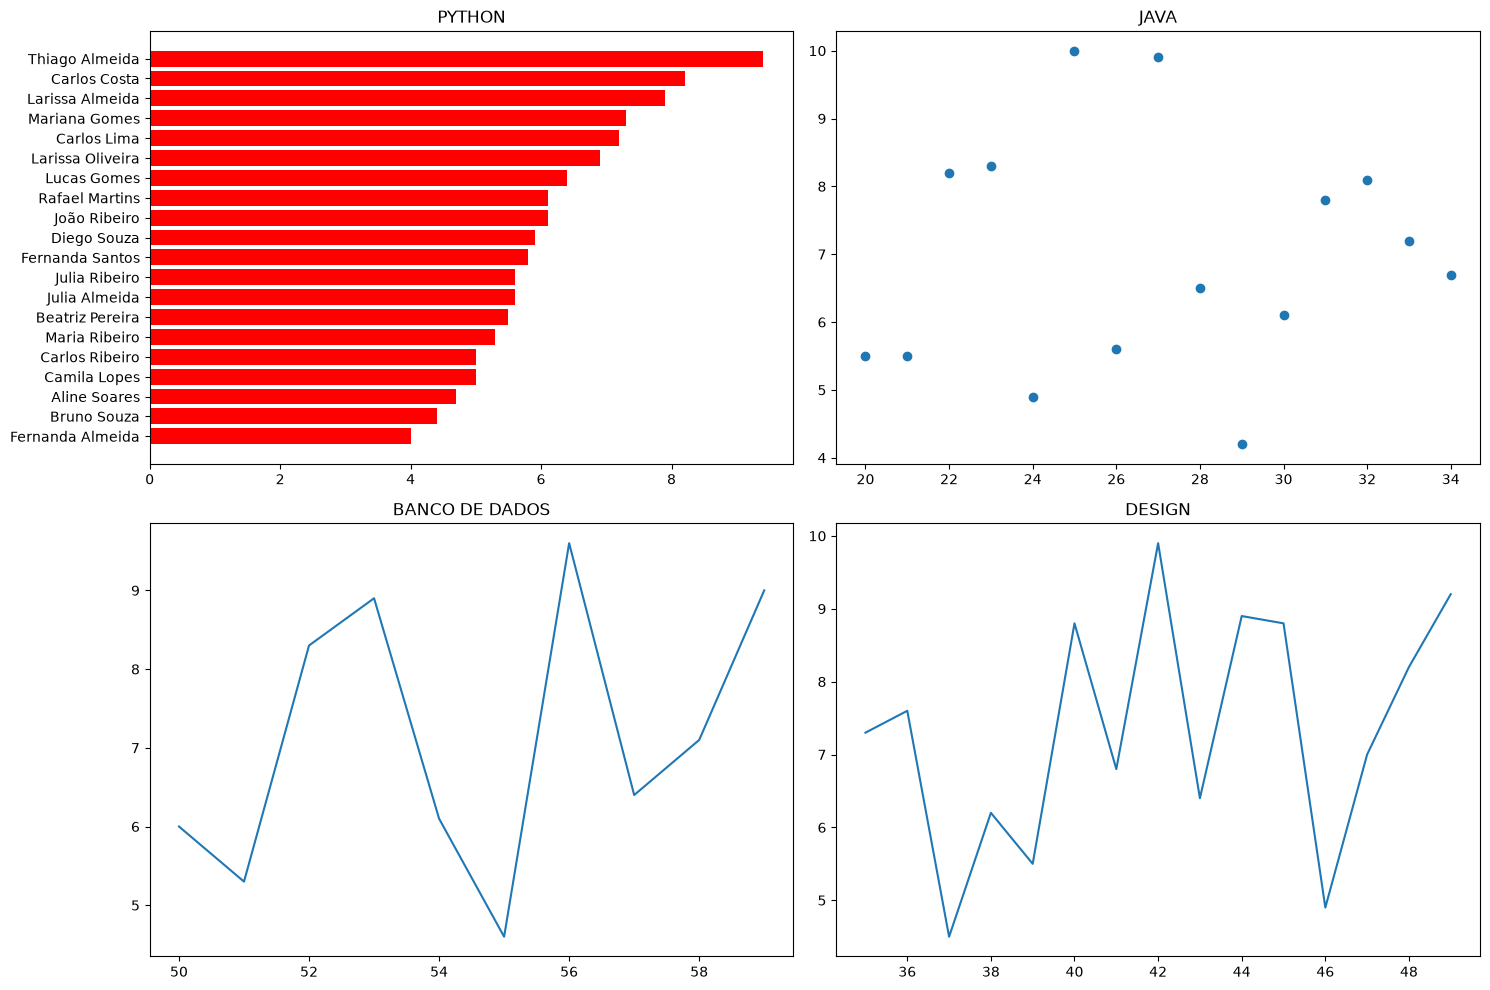

In [41]:
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
#[[0,0] [0,1]
#[1,0] [1,1]]

df_python =  df_alunos[df_alunos["Curso"] == "Python"].sort_values(
    by="Media_Final"
)
df_java = df_alunos[df_alunos["Curso"] == "Java"]
df_banco_de_dados = df_alunos[df_alunos["Curso"] == "Banco de Dados"]
df_design = df_alunos[df_alunos["Curso"] == "Design"]

axs[0,0].barh(
    df_python['Nome'],
    df_python["Media_Final"],
    color='r',
    linewidth=5,
)
axs[0,0].set_title("PYTHON")

axs[0,1].scatter(df_java.index, df_java["Media_Final"])
axs[0,1].set_title("JAVA")

axs[1,0].plot(df_banco_de_dados.index, df_banco_de_dados["Media_Final"])
axs[1,0].set_title("BANCO DE DADOS")

axs[1,1].plot(df_design.index, df_design["Media_Final"])
axs[1,1].set_title("DESIGN")

plt.tight_layout()

fig.savefig("media_final_alunos_cursos.png")

plt.show()